## Setup and imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt          # not used yet, needed for the visualization step
from collections import Counter
from functools import partial
from sklearn.datasets import make_moons


def lp_distance(v1, v2, p=2):
    """General Lp norm distance between two vectors.
    p=1 -> Manhattan, p=2 -> Euclidean."""
    return float(np.sum(np.abs(v1 - v2) ** p) ** (1 / p))


# Bind p so each has the two-argument form f(v1, v2) that knn_predict expects
euclidean = partial(lp_distance, p=2)
manhattan = partial(lp_distance, p=1)

## Part 1: k-NN

In [ ]:
def knn_predict(X_train, y_train, X_test, y_test, k, distance_func):
    """
    Predict the class of ONE test record with k-NN.

    X_train : (n, 2) ndarray   training inputs (as returned by make_moons)
    y_train : (n,)  ndarray    training labels, 0/1
    X_test  : (2,)  ndarray    a single test record
    y_test  : the true label of the test record. Accepted only because the
              assignment's signature includes it. It is NOT used for the
              prediction (using it would be label leakage).
    k       : number of neighbors
    distance_func : f(v1, v2) -> float
    Returns the predicted class (int).
    """
    if not 1 <= k <= len(X_train):
        raise ValueError(f"k must be between 1 and {len(X_train)}, got {k}")

    # 1. Distance from the test record to every training record
    distances = np.array([distance_func(x, X_test) for x in X_train])

    # 2. Indices of the k nearest. A stable sort means that exact distance
    #    ties are broken by training-set order, so results are reproducible.
    order = np.argsort(distances, kind="stable")
    nearest = order[:k]

    # 3. Labels of those neighbors, still ordered nearest -> farthest
    neighbor_labels = y_train[nearest]

    # 4. Vote
    votes = Counter(neighbor_labels.tolist())

    # 5. Find the winning class(es)
    top_count = max(votes.values())
    tied = [c for c, v in votes.items() if v == top_count]
    if len(tied) == 1:
        return tied[0]

    # 6. Tie-break: among the tied classes, pick the one whose member is
    #    closest to the test record (closer points are better evidence).
    for label in neighbor_labels:          # nearest first
        if label in tied:
            return int(label)
        

All knn_predict tests passed.


In [4]:
# --- Test 1: hand-checkable example ---
X_small = np.array([[0, 0], [1, 0], [5, 5], [6, 5]], dtype=float)
y_small = np.array([0, 0, 1, 1])

# Near the class-0 cluster: k=3 gives neighbors (0,0), (1,0), then one class-1 point -> 2 votes vs 1
assert knn_predict(X_small, y_small, np.array([0.5, 0.2]), 0, 3, euclidean) == 0
# Near the class-1 cluster
assert knn_predict(X_small, y_small, np.array([5.5, 5.0]), 1, 3, euclidean) == 1

# --- Test 2: tie-break (even k, one vote each -> nearest neighbor wins) ---
X_tie = np.array([[0, 0], [2, 0]], dtype=float)
y_tie = np.array([0, 1])
assert knn_predict(X_tie, y_tie, np.array([0.5, 0.0]), 0, 2, euclidean) == 0  # closer to class 0
assert knn_predict(X_tie, y_tie, np.array([1.5, 0.0]), 1, 2, euclidean) == 1  # closer to class 1

# --- Test 3: with k=1, every training point should predict its own label ---
np.random.seed(42)
X, y = make_moons(n_samples=200, noise=0.15)
preds = [knn_predict(X, y, X[i], y[i], 1, euclidean) for i in range(len(X))]
assert np.array_equal(preds, y)

# --- Test 4: bad k is rejected ---
try:
    knn_predict(X, y, X[0], y[0], 0, euclidean)
    raise AssertionError("expected ValueError")
except ValueError:
    pass

print("All knn_predict tests passed.")

All knn_predict tests passed.


In [5]:
def plot_knn(X_train, y_train, k, distance_func, title=None, grid_size=100, ax=None):
    """
    Visualize a 2D binary k-NN model.

    Colors a grid_size x grid_size grid of inputs by the predicted class
    (this shows the decision regions and boundary), then overlays the
    training points colored by their true class.
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))

    # 1. Build a regular grid that covers the data, with a small margin
    margin = 0.5
    x_min, x_max = X_train[:, 0].min() - margin, X_train[:, 0].max() + margin
    y_min, y_max = X_train[:, 1].min() - margin, X_train[:, 1].max() + margin
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, grid_size),
                         np.linspace(y_min, y_max, grid_size))
    grid_points = np.column_stack([xx.ravel(), yy.ravel()])   # shape (grid_size**2, 2)

    # 2. Predict the class at every grid point.
    #    y_test is required by the signature but unused, so pass a dummy 0.
    grid_preds = np.array([
        knn_predict(X_train, y_train, pt, 0, k, distance_func)
        for pt in grid_points
    ]).reshape(xx.shape)

    # 3. Shade the decision regions; the color change is the decision boundary
    ax.contourf(xx, yy, grid_preds, levels=[-0.5, 0.5, 1.5],
                colors=["#ffb3b3", "#b3c6ff"], alpha=0.8)

    # 4. Overlay training points, different color AND marker per class
    ax.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1],
               c="red", marker="o", edgecolor="k", label="class 0")
    ax.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1],
               c="blue", marker="s", edgecolor="k", label="class 1")

    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(title or f"k-NN decision boundary (k={k})")
    ax.legend()
    return ax

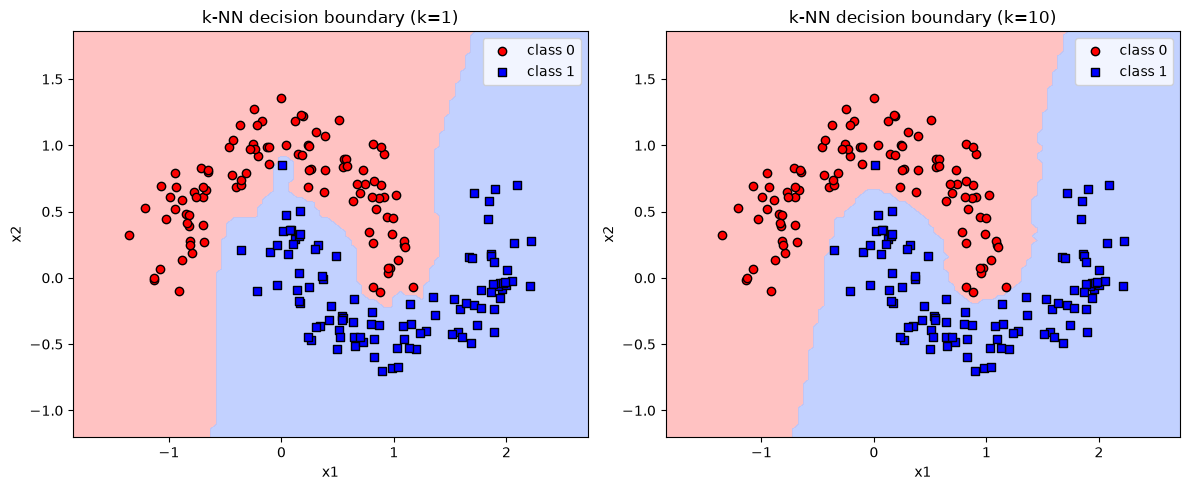

Visualization sanity check passed.


In [6]:
np.random.seed(42)
X, y = make_moons(n_samples=200, noise=0.15)

# Side-by-side: k=1 vs k=10 with Euclidean distance
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_knn(X, y, k=1, distance_func=euclidean, ax=axes[0])
plot_knn(X, y, k=10, distance_func=euclidean, ax=axes[1])
plt.tight_layout()
plt.show()

# Sanity check: at k=1, every training point sits inside a region of its own color
for i in range(len(X)):
    assert knn_predict(X, y, X[i], 0, 1, euclidean) == y[i]
print("Visualization sanity check passed.")

In [7]:
def knn_errors(X, y, k, distance_func):
    """
    Compute (training_error, test_error) for a k-NN model on dataset (X, y).

    Training error: train on ALL records, predict ALL records, and
    report the fraction mispredicted.

    Test error: leave-one-out cross validation (LOOCV). For each record R,
    train on every other record, predict R, and report the fraction of
    records mispredicted.
    """
    n = len(X)

    # --- Training error: each record may be its own nearest neighbor ---
    train_wrong = 0
    for i in range(n):
        pred = knn_predict(X, y, X[i], y[i], k, distance_func)
        train_wrong += (pred != y[i])
    train_error = train_wrong / n

    # --- Test error via LOOCV: record i is held out of the training data ---
    test_wrong = 0
    for i in range(n):
        X_rest = np.delete(X, i, axis=0)   # all records except i
        y_rest = np.delete(y, i, axis=0)
        pred = knn_predict(X_rest, y_rest, X[i], y[i], k, distance_func)
        test_wrong += (pred != y[i])
    test_error = test_wrong / n

    return train_error, test_error

In [8]:
# --- Test 1: hand-checkable example (same 4 points as before) ---
# k=1: each point's nearest neighbor is its cluster mate -> both errors 0.
assert knn_errors(X_small, y_small, 1, euclidean) == (0.0, 0.0)

# k=3: training error is 0 (each point outvotes the far cluster with itself
# and its mate), but with LOOCV the held-out point has only ONE same-class
# neighbor left vs. two from the other cluster -> every prediction is wrong.
assert knn_errors(X_small, y_small, 3, euclidean) == (0.0, 1.0)

# --- Test 2: on make_moons, k=1 training error must be exactly 0 ---
np.random.seed(42)
X, y = make_moons(n_samples=200, noise=0.15)
train_err, test_err = knn_errors(X, y, 1, euclidean)
assert train_err == 0.0
assert 0.0 <= test_err <= 1.0

# --- Test 3: print the errors for a few k values to eyeball the trend ---
for k in [1, 3, 5, 10]:
    tr, te = knn_errors(X, y, k, euclidean)
    print(f"k={k:>2}  train error={tr:.3f}  test (LOOCV) error={te:.3f}")

print("knn_errors tests passed.")

k= 1  train error=0.000  test (LOOCV) error=0.020
k= 3  train error=0.010  test (LOOCV) error=0.010
k= 5  train error=0.005  test (LOOCV) error=0.005
k=10  train error=0.005  test (LOOCV) error=0.010
knn_errors tests passed.


In [13]:
def knn_votes(X_train, y_train, x_test, k, distance_func):
    """Return {0: votes_for_class_0, 1: votes_for_class_1} among the k nearest neighbors."""
    distances = np.array([distance_func(x, x_test) for x in X_train])
    nearest = np.argsort(distances, kind="stable")[:k]      # same selection as knn_predict
    labels = y_train[nearest]
    return {0: int(np.sum(labels == 0)), 1: int(np.sum(labels == 1))}

## Part 2: Perceptron and neuron

In [9]:
def train_perceptron(training_record, learning_rate, w1, w2, b):
    """
    One perceptron-rule update from a SINGLE training record.

    training_record : (x1, x2, y) with y in {0, 1}
    Returns the updated (w1, w2, b).
    """
    x1, x2, y = training_record

    # 1. Forward pass: weighted sum, then a step activation.
    #    Convention: output 1 when the sum is >= 0, else 0.
    z = w1 * x1 + w2 * x2 + b
    y_hat = 1 if z >= 0 else 0

    # 2. Error is +1, 0, or -1
    error = y - y_hat

    # 3. Perceptron rule: nudge each parameter in proportion to the error
    #    and to its input. (The bias acts like a weight on a constant input of 1.)
    w1 = w1 + learning_rate * error * x1
    w2 = w2 + learning_rate * error * x2
    b = b + learning_rate * error

    return w1, w2, b

In [10]:
# --- Test 1: missed positive (predicts 0, label 1) -> move toward the input ---
w1, w2, b = train_perceptron((1.0, 1.0, 1), 0.1, 0.0, 0.0, -1.0)
assert np.allclose([w1, w2, b], [0.1, 0.1, -0.9])

# --- Test 2: false positive (predicts 1, label 0) -> move away from the input ---
w1, w2, b = train_perceptron((1.0, 1.0, 0), 0.1, 1.0, 1.0, 0.0)
assert np.allclose([w1, w2, b], [0.9, 0.9, -0.1])

# --- Test 3: correct prediction -> parameters unchanged ---
w1, w2, b = train_perceptron((2.0, 2.0, 1), 0.1, 1.0, 1.0, 0.0)
assert (w1, w2, b) == (1.0, 1.0, 0.0)

# --- Test 4: learns the AND function (linearly separable) ---
and_data = [(0, 0, 0), (0, 1, 0), (1, 0, 0), (1, 1, 1)]
w1, w2, b = 0.0, 0.0, 0.0
for epoch in range(100):
    for record in and_data:
        w1, w2, b = train_perceptron(record, 0.1, w1, w2, b)

def n_errors(data, w1, w2, b):
    return sum((1 if w1 * x1 + w2 * x2 + b >= 0 else 0) != y for x1, x2, y in data)

assert n_errors(and_data, w1, w2, b) == 0
print(f"Learned w1={w1:.2f}, w2={w2:.2f}, b={b:.2f}")
print("train_perceptron tests passed.")

Learned w1=0.20, w2=0.10, b=-0.20
train_perceptron tests passed.


In [25]:
# --- Activation functions (forward) ---
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def relu(z):
    return np.maximum(0.0, z)

# --- Activation derivatives, each taking z (the pre-activation value) ---
def sigmoid_derivative(z):
    s = sigmoid(z)
    return s * (1.0 - s)

def tanh_derivative(z):
    return 1.0 - np.tanh(z) ** 2

def relu_derivative(z):
    return 1.0 if z > 0 else 0.0          # derivative at exactly 0 is set to 0, per the assignment

# --- Cost derivatives, each taking (a, y) and returning dC/da ---
def squared_error_derivative(a, y):
    # C = 0.5 * (a - y)^2
    return a - y

def cross_entropy_derivative(a, y, eps=1e-12):
    # C = -[y*ln(a) + (1-y)*ln(1-a)]
    a = np.clip(a, eps, 1 - eps)           # avoid division by zero at a = 0 or 1
    return (a - y) / (a * (1 - a))


def train_neuron(training_record, learning_rate, w, b,
                 cost_derivative, activation_derivative, activation=sigmoid,
                 return_grad=False):
    """
    One gradient-descent update for a single-input neuron, from ONE record.
    Returns (w, b), or (w, b, grad_w, grad_b) if return_grad=True.
    """
    x, y = training_record

    # 1. Forward pass
    z = w * x + b
    a = activation(z)

    # 2. Backward pass (chain rule)
    dC_da = cost_derivative(a, y)
    da_dz = activation_derivative(z)
    delta = dC_da * da_dz
    grad_w = delta * x
    grad_b = delta

    # 3. Step downhill
    w = w - learning_rate * grad_w
    b = b - learning_rate * grad_b
    return (w, b, grad_w, grad_b) if return_grad else (w, b)

In [12]:
# --- Test 1: sigmoid + squared error, worked by hand ---
# w=0, b=0, x=1, y=1 -> z=0, a=0.5, dC/da=-0.5, da/dz=0.25, delta=-0.125
w, b = train_neuron((1.0, 1.0), 1.0, 0.0, 0.0,
                    squared_error_derivative, sigmoid_derivative, activation=sigmoid)
assert np.allclose([w, b], [0.125, 0.125])

# --- Test 2: sigmoid + cross-entropy, same record ---
# dC/da=-2, da/dz=0.25, delta=-0.5 (which equals a - y)
w, b = train_neuron((1.0, 1.0), 1.0, 0.0, 0.0,
                    cross_entropy_derivative, sigmoid_derivative, activation=sigmoid)
assert np.allclose([w, b], [0.5, 0.5])

# --- Test 3: ReLU with z exactly 0 -> derivative is 0, parameters unchanged ---
w, b = train_neuron((1.0, 1.0), 1.0, 0.0, 0.0,
                    squared_error_derivative, relu_derivative, activation=relu)
assert (w, b) == (0.0, 0.0)

# --- Test 4: tanh derivative matches a numerical derivative ---
z0, h = 0.7, 1e-6
numeric = (np.tanh(z0 + h) - np.tanh(z0 - h)) / (2 * h)
assert np.isclose(tanh_derivative(z0), numeric)

# --- Test 5: repeated updates reduce the error (learn y = sigmoid(2x - 1)) ---
xs = np.linspace(0, 1, 20)
ys = sigmoid(2 * xs - 1)

def mse(w, b):
    return np.mean((sigmoid(w * xs + b) - ys) ** 2)

w, b = 0.0, 0.0
initial = mse(w, b)
for epoch in range(3000):
    for x_i, y_i in zip(xs, ys):
        w, b = train_neuron((x_i, y_i), 1.0, w, b,
                            squared_error_derivative, sigmoid_derivative, activation=sigmoid)
assert mse(w, b) < initial / 10
print(f"Learned w={w:.2f}, b={b:.2f}  (true values: 2, -1)")
print("train_neuron tests passed.")

Learned w=2.00, b=-1.00  (true values: 2, -1)
train_neuron tests passed.


In [26]:
# Activation / derivative pairs, to be passed around together
ACTIVATIONS = {
    "sigmoid": (sigmoid, sigmoid_derivative),
    "tanh":    (np.tanh, tanh_derivative),
    "relu":    (relu, relu_derivative),
}
COSTS = {
    "squared error": squared_error_derivative,
    "cross-entropy": cross_entropy_derivative,
}

def fit_neuron(x, y, activation_name, cost_name, learning_rate, epochs, w0, b0):
    """
    Train with train_neuron, one record at a time, in the given order.
    Returns arrays with one row per update (n_records * epochs rows):
      w, b (parameters AFTER the update), grad_w, grad_b (gradients used for it).
    """
    activation, activation_derivative = ACTIVATIONS[activation_name]
    cost_derivative = COSTS[cost_name]
    w, b = w0, b0
    ws, bs, gws, gbs = [], [], [], []
    for _ in range(epochs):
        for xi, yi in zip(x, y):
            w, b, gw, gb = train_neuron((xi, yi), learning_rate, w, b,
                                        cost_derivative, activation_derivative,
                                        activation=activation, return_grad=True)
            ws.append(w); bs.append(b); gws.append(gw); gbs.append(gb)
    return np.array(ws), np.array(bs), np.array(gws), np.array(gbs)

def mean_squared_error(x, y, activation_name, w, b):
    """Evaluation metric on the raw data, used to compare models fairly."""
    activation, _ = ACTIVATIONS[activation_name]
    return float(np.mean((activation(w * x + b) - y) ** 2))

## Experiments Q3 to Q5 (k-NN)

In [14]:
np.random.seed(42)                       # must come immediately before make_moons
X, y = make_moons(n_samples=200, noise=0.15)

test_points = [(0.40, 0.45), (0.08, 0.78), (0.75, -0.15)]
metrics = {"Euclidean": euclidean, "Manhattan": manhattan}

print(f"{'test point':<14}{'metric':<11}{'k':<3}{'votes (c0, c1)':<16}predicted")
for pt in test_points:
    x_test = np.array(pt)
    for name, dist in metrics.items():
        for k in [1, 3, 5]:
            v = knn_votes(X, y, x_test, k, dist)
            pred = knn_predict(X, y, x_test, -1, k, dist)   # y_test unused, dummy -1
            print(f"{str(pt):<14}{name:<11}{k:<3}({v[0]}, {v[1]}){'':<9}{pred}")

test point    metric     k  votes (c0, c1)  predicted
(0.4, 0.45)   Euclidean  1  (1, 0)         0
(0.4, 0.45)   Euclidean  3  (1, 2)         1
(0.4, 0.45)   Euclidean  5  (1, 4)         1
(0.4, 0.45)   Manhattan  1  (1, 0)         0
(0.4, 0.45)   Manhattan  3  (1, 2)         1
(0.4, 0.45)   Manhattan  5  (1, 4)         1
(0.08, 0.78)  Euclidean  1  (0, 1)         1
(0.08, 0.78)  Euclidean  3  (2, 1)         0
(0.08, 0.78)  Euclidean  5  (4, 1)         0
(0.08, 0.78)  Manhattan  1  (0, 1)         1
(0.08, 0.78)  Manhattan  3  (2, 1)         0
(0.08, 0.78)  Manhattan  5  (4, 1)         0
(0.75, -0.15) Euclidean  1  (1, 0)         0
(0.75, -0.15) Euclidean  3  (1, 2)         1
(0.75, -0.15) Euclidean  5  (2, 3)         1
(0.75, -0.15) Manhattan  1  (0, 1)         1
(0.75, -0.15) Manhattan  3  (1, 2)         1
(0.75, -0.15) Manhattan  5  (2, 3)         1


In [15]:
X_demo = np.array([[1.2, 1.2],     # class 0: diagonal from the origin
                   [2.0, 0.0]])    # class 1: along an axis
y_demo = np.array([0, 1])
x_test = np.array([0.0, 0.0])

for name, dist in metrics.items():
    d = [round(dist(p, x_test), 3) for p in X_demo]
    print(f"{name:<10} distances={d}  prediction={knn_predict(X_demo, y_demo, x_test, -1, 1, dist)}")
    
# votes always sum to k, and the winner matches knn_predict (k is odd, so no ties)
for pt in test_points:
    for dist in metrics.values():
        for k in [1, 3, 5]:
            v = knn_votes(X, y, np.array(pt), k, dist)
            assert v[0] + v[1] == k
            assert (0 if v[0] > v[1] else 1) == knn_predict(X, y, np.array(pt), -1, k, dist)

# the minimal example really does disagree
assert knn_predict(X_demo, y_demo, x_test, -1, 1, euclidean) == 0
assert knn_predict(X_demo, y_demo, x_test, -1, 1, manhattan) == 1
print("Q3 tests passed.")

Euclidean  distances=[1.697, 2.0]  prediction=0
Manhattan  distances=[2.4, 2.0]  prediction=1
Q3 tests passed.


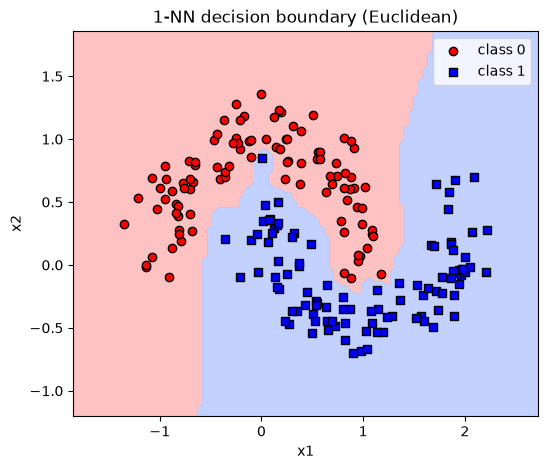

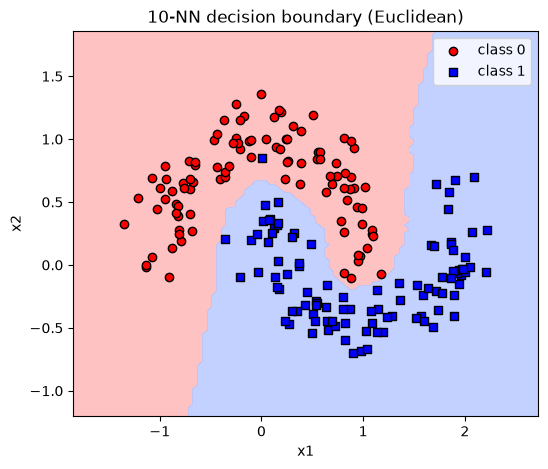

In [16]:
np.random.seed(42)                       # must come immediately before make_moons
X, y = make_moons(n_samples=200, noise=0.15)

# Separate figures, as the assignment asks
plot_knn(X, y, k=1, distance_func=euclidean, title="1-NN decision boundary (Euclidean)")
plt.show()

plot_knn(X, y, k=10, distance_func=euclidean, title="10-NN decision boundary (Euclidean)")
plt.show()

In [17]:
# Two training records at the SAME location with DIFFERENT labels
X_conflict = np.array([[0.0, 0.0], [0.0, 0.0]])
y_conflict = np.array([0, 1])

for k in [1, 2]:
    preds = [knn_predict(X_conflict, y_conflict, X_conflict[i], y_conflict[i], k, euclidean)
             for i in range(2)]
    err = np.mean(np.array(preds) != y_conflict)
    print(f"k={k}: predictions={preds}, true={y_conflict.tolist()}, training error={err}")

k=1: predictions=[0, 0], true=[0, 1], training error=0.5
k=2: predictions=[0, 0], true=[0, 1], training error=0.5


class counts: [100 100]


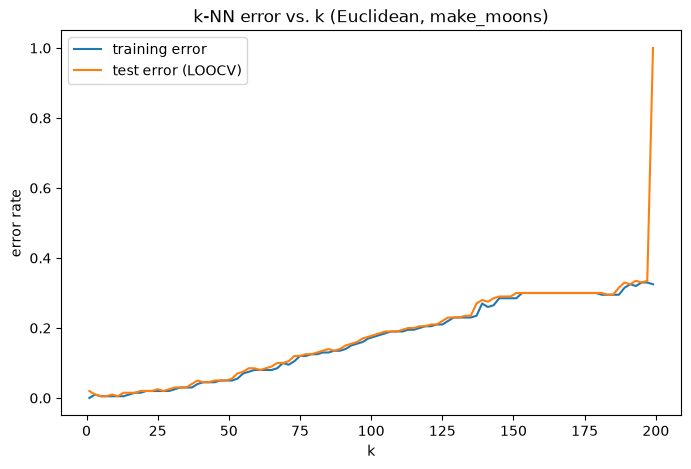

k = n = 200: training error = 0.000
k = n-1 = 199: LOOCV test error = 1.000


In [18]:
np.random.seed(42)                       # must come immediately before make_moons
X, y = make_moons(n_samples=200, noise=0.15)
n = len(X)
print("class counts:", np.bincount(y))   # expect [100 100]

ks = list(range(1, n, 2))                # 1, 3, ..., 199 (199 = n-1, the LOOCV maximum)
train_errs, test_errs = [], []
for k in ks:
    tr, te = knn_errors(X, y, k, euclidean)
    train_errs.append(tr)
    test_errs.append(te)

plt.figure(figsize=(8, 5))
plt.plot(ks, train_errs, label="training error")
plt.plot(ks, test_errs, label="test error (LOOCV)")
plt.xlabel("k")
plt.ylabel("error rate")
plt.title("k-NN error vs. k (Euclidean, make_moons)")
plt.legend()
plt.show()

# The full-dataset case, k = n, for training error only (LOOCV can't use it)
wrong = sum(knn_predict(X, y, X[i], y[i], n, euclidean) != y[i] for i in range(n))
print(f"k = n = {n}: training error = {wrong / n:.3f}")
print(f"k = n-1 = {n-1}: LOOCV test error = {test_errs[-1]:.3f}")

## Experiments Q7 to Q8 (perceptron)

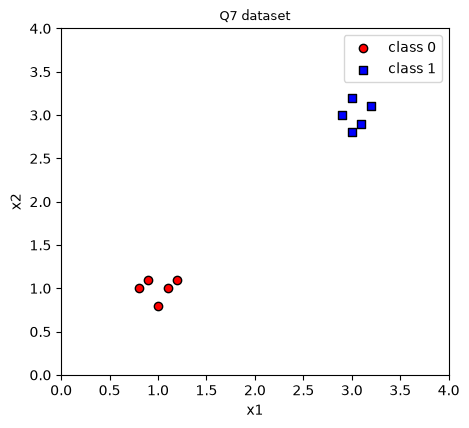

initial errors: 10 of 10
call   0: w1=-1.000 w2=-1.000 b=+4.000  errors=10
call   1: w1=-1.090 w2=-1.110 b=+3.900  errors=10
call   2: w1=-1.190 w2=-1.190 b=+3.800  errors=10
call   3: w1=-1.300 w2=-1.290 b=+3.700  errors=10
call   4: w1=-1.380 w2=-1.390 b=+3.600  errors=10
call   5: w1=-1.500 w2=-1.500 b=+3.500  errors=10
call   6: w1=-1.190 w2=-1.210 b=+3.600  errors=10
call   7: w1=-0.890 w2=-0.890 b=+3.700  errors=10
call   8: w1=-0.600 w2=-0.590 b=+3.800  errors=5
call   9: w1=-0.600 w2=-0.590 b=+3.800  errors=5
call  10: w1=-0.600 w2=-0.590 b=+3.800  errors=5
call  11: w1=-0.690 w2=-0.700 b=+3.700  errors=10
call  12: w1=-0.790 w2=-0.780 b=+3.600  errors=10
call  13: w1=-0.900 w2=-0.880 b=+3.500  errors=10
call  14: w1=-0.980 w2=-0.980 b=+3.400  errors=10
call  15: w1=-1.100 w2=-1.090 b=+3.300  errors=10
call  16: w1=-0.790 w2=-0.800 b=+3.400  errors=10
call  17: w1=-0.490 w2=-0.480 b=+3.500  errors=5
call  18: w1=-0.490 w2=-0.480 b=+3.500  errors=5
call  19: w1=-0.490 w2=-0.480 

In [19]:
# --- Dataset from the assignment: schema (x1, x2, y) ---
data = [(0.9, 1.1, 0), (1.0, 0.8, 0), (1.1, 1.0, 0), (0.8, 1.0, 0), (1.2, 1.1, 0),
        (3.1, 2.9, 1), (3.0, 3.2, 1), (2.9, 3.0, 1), (3.2, 3.1, 1), (3.0, 2.8, 1)]

def count_errors(data, w1, w2, b):
    """Number of misclassified records (same z >= 0 -> class 1 rule as train_perceptron)."""
    return sum((1 if w1 * x1 + w2 * x2 + b >= 0 else 0) != y for x1, x2, y in data)

def run_perceptron(data, lr, init, epochs):
    """Call train_perceptron on records one by one. Returns a history of
    (w1, w2, b, errors on the WHOLE dataset); entry 0 is the initial state,
    entry i is the state after the i-th call."""
    w1, w2, b = init
    history = [(w1, w2, b, count_errors(data, w1, w2, b))]
    for _ in range(epochs):
        for record in data:                       # records in the given order
            w1, w2, b = train_perceptron(record, lr, w1, w2, b)
            history.append((w1, w2, b, count_errors(data, w1, w2, b)))
    return history

def plot_boundary(ax, data, w1, w2, b, title):
    """Scatter the data and draw the line w1*x1 + w2*x2 + b = 0."""
    pts = np.array([(x1, x2) for x1, x2, _ in data])
    labels = np.array([y for _, _, y in data])
    ax.scatter(*pts[labels == 0].T, c="red", marker="o", edgecolor="k", label="class 0")
    ax.scatter(*pts[labels == 1].T, c="blue", marker="s", edgecolor="k", label="class 1")
    xx, yy = np.meshgrid(np.linspace(0, 4, 200), np.linspace(0, 4, 200))
    ax.contour(xx, yy, w1 * xx + w2 * yy + b, levels=[0], colors="green", linewidths=2)
    ax.set_xlim(0, 4); ax.set_ylim(0, 4)
    ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_title(title, fontsize=9)

# 1. Scatterplot of the dataset
fig, ax = plt.subplots(figsize=(5, 4.5))
plot_boundary(ax, data, 0, 0, 1, "Q7 dataset")   # w=0 -> no line is drawn
ax.legend()
plt.show()

# 2. A worst-case start: z = -x1 - x2 + 4 puts class 0 on the "1" side and class 1 on the "0" side
init = (-1.0, -1.0, 4.0)
print("initial errors:", count_errors(data, *init), "of", len(data))

# 3. Train, one record per call, error on the full dataset after every call
history = run_perceptron(data, lr=0.1, init=init, epochs=30)
for i, (w1, w2, b, err) in enumerate(history[:25]):
    print(f"call {i:>3}: w1={w1:+.3f} w2={w2:+.3f} b={b:+.3f}  errors={err}")

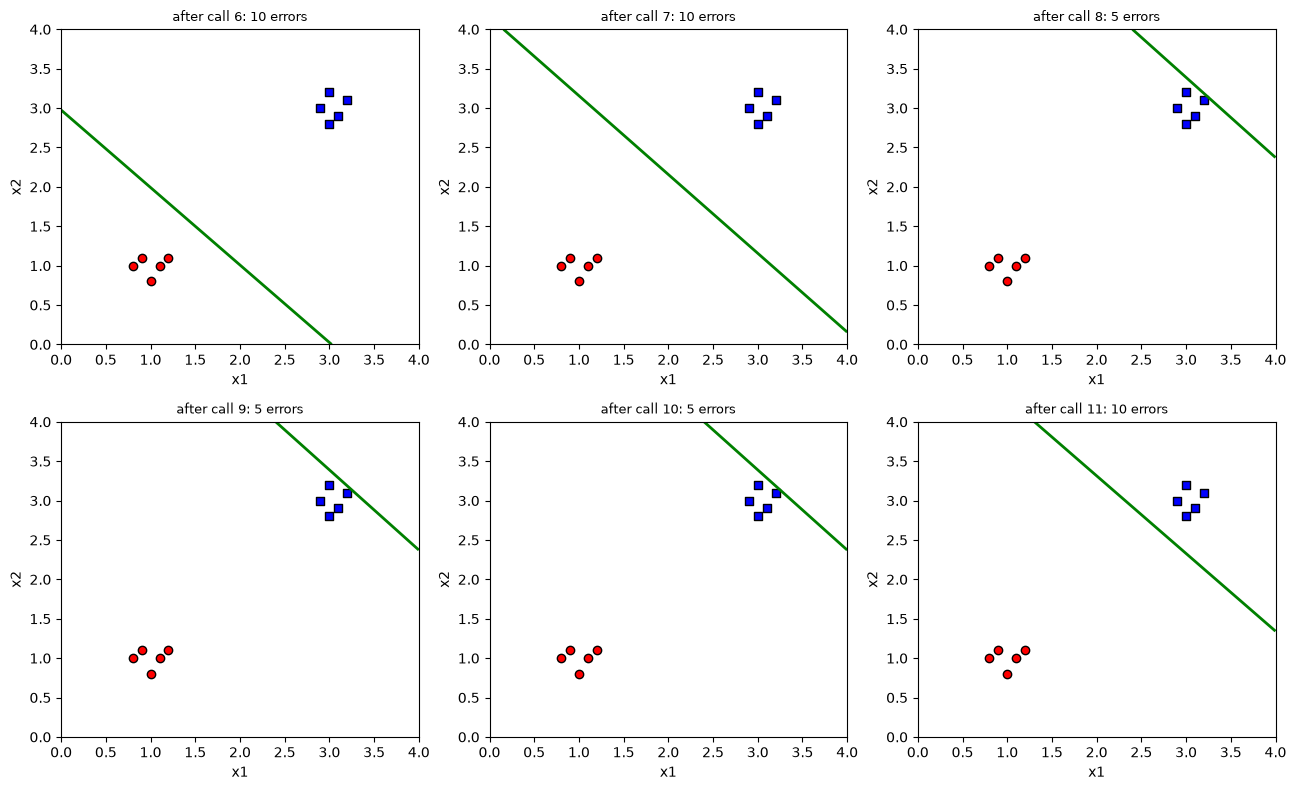

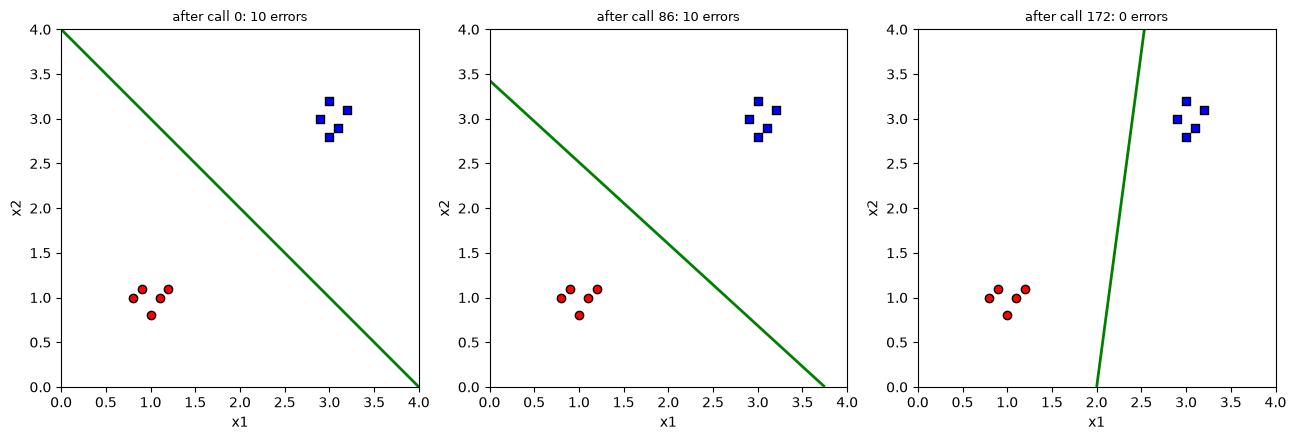

In [20]:
# Calls 6 to 11: the error drops from 10 to 5 and then goes back up
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, i in zip(axes.ravel(), range(6, 12)):
    w1, w2, b, err = history[i]
    plot_boundary(ax, data, w1, w2, b, f"after call {i}: {err} errors")
plt.tight_layout()
plt.show()

# The start, the middle, and the end of training
first_zero = next(i for i, h in enumerate(history) if h[3] == 0)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, i in zip(axes, [0, first_zero // 2, first_zero]):
    w1, w2, b, err = history[i]
    plot_boundary(ax, data, w1, w2, b, f"after call {i}: {err} errors")
plt.tight_layout()
plt.show()

Minimal training error: 0 errors, first reached at call 172
w1=0.150, w2=-0.020, b=-0.300


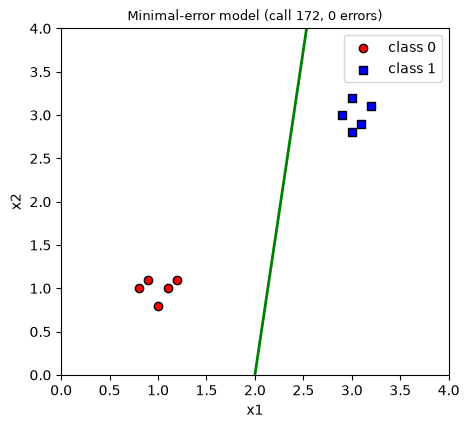

In [21]:
best_i = min(range(len(history)), key=lambda i: (history[i][3], i))   # fewest errors, earliest call
w1, w2, b, err = history[best_i]
print(f"Minimal training error: {err} errors, first reached at call {best_i}")
print(f"w1={w1:.3f}, w2={w2:.3f}, b={b:.3f}")

fig, ax = plt.subplots(figsize=(5, 4.5))
plot_boundary(ax, data, w1, w2, b, f"Minimal-error model (call {best_i}, {err} errors)")
ax.legend()
plt.show()

In [22]:
# The start really has the maximum number of errors
assert count_errors(data, *init) == len(data)

# History bookkeeping: 1 initial state + 10 calls per epoch
assert len(history) == 1 + 30 * len(data)

# Each recorded error count matches a fresh recount for that call's parameters
for w1, w2, b, err in history:
    assert err == count_errors(data, w1, w2, b)

# The best model is perfect, and its error equals the minimum over the history
assert history[best_i][3] == 0
assert history[best_i][3] == min(h[3] for h in history)
print("Q7 tests passed.")

Q7 tests passed.


initial errors: 10 of 11
minimum errors over all calls: 1 (first at call 189 )
ever reached 0 errors? False
errors after the last 33 calls: [3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3]


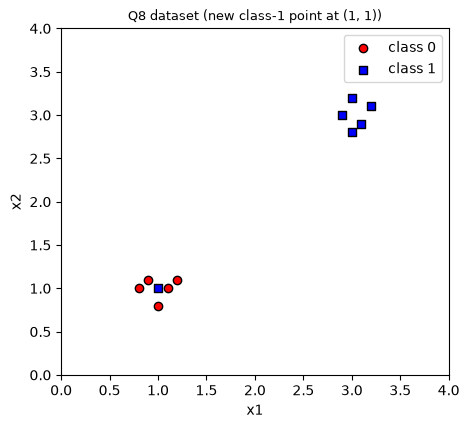

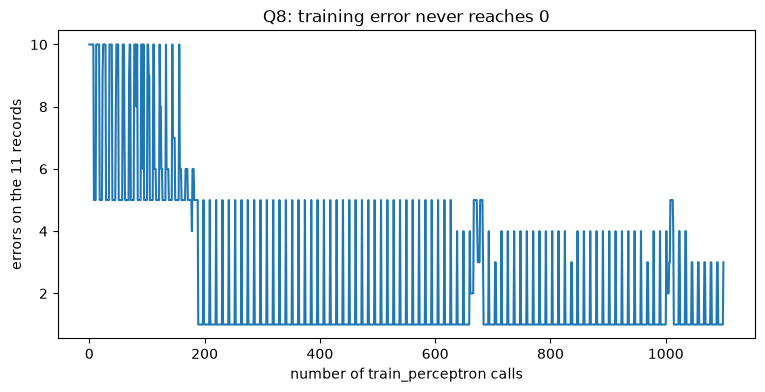

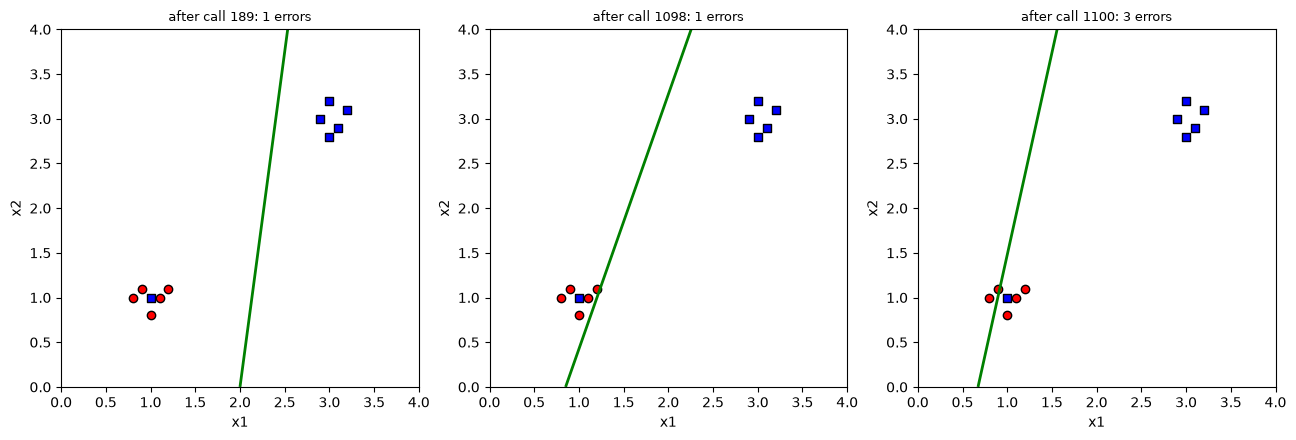

In [23]:
# Same data plus the new record: a class-1 point at (1.0, 1.0)
data2 = data + [(1.0, 1.0, 1)]

# Same starting boundary and learning rate as Q7, so the two experiments are comparable
init = (-1.0, -1.0, 4.0)
history2 = run_perceptron(data2, lr=0.1, init=init, epochs=100)   # 100 passes = 1100 calls
errors2 = [h[3] for h in history2]

print("initial errors:", errors2[0], "of", len(data2))
print("minimum errors over all calls:", min(errors2), "(first at call", errors2.index(min(errors2)), ")")
print("ever reached 0 errors?", 0 in errors2)
print("errors after the last 33 calls:", errors2[-33:])

# 1. Scatterplot with the new point
fig, ax = plt.subplots(figsize=(5, 4.5))
plot_boundary(ax, data2, 0, 0, 1, "Q8 dataset (new class-1 point at (1, 1))")
ax.legend()
plt.show()

# 2. Error on the full dataset after every call
plt.figure(figsize=(9, 4))
plt.plot(errors2)
plt.xlabel("number of train_perceptron calls")
plt.ylabel("errors on the 11 records")
plt.title("Q8: training error never reaches 0")
plt.show()

# 3. Best model found (fewest errors, earliest call) and a few late boundaries
best_i = min(range(len(history2)), key=lambda i: (history2[i][3], i))
w1, w2, b, err = history2[best_i]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, i in zip(axes, [best_i, len(history2) - 3, len(history2) - 1]):
    w1, w2, b, err = history2[i]
    plot_boundary(ax, data2, w1, w2, b, f"after call {i}: {err} errors")
plt.tight_layout()
plt.show()

In [24]:
# The new point is exactly the centroid of the class-0 points
class0 = np.array([(x1, x2) for x1, x2, y in data if y == 0])
assert np.allclose(class0.mean(axis=0), [1.0, 1.0])

# Training never reaches 0 errors, and 1 is the best it finds
assert 0 not in errors2
assert min(errors2) == 1

# Each recorded error count matches a recount for that call's parameters
for w1, w2, b, e in history2:
    assert e == count_errors(data2, w1, w2, b)

# The Q7 dataset, by contrast, is separable: its experiment did reach 0
assert 0 in [h[3] for h in run_perceptron(data, lr=0.1, init=init, epochs=30)]
print("Q8 tests passed.")

Q8 tests passed.


In [30]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML

def animate_fit(x, y, activation_name, cost_name, learning_rate,
                n_updates, step, w0, b0, true_fn=lambda t: 2 * t + 3):
    """
    Animate the model's output curve as training proceeds.
    One frame per `step` updates, covering the first `n_updates` updates.
    Returns a FuncAnimation (display it with HTML(ani.to_jshtml())).
    """
    # 1. Train once, recording the parameters after every update
    epochs = int(np.ceil(n_updates / len(x)))
    ws, bs, _, _ = fit_neuron(x, y, activation_name, cost_name,
                              learning_rate, epochs, w0, b0)
    ws = np.concatenate([[w0], ws[:n_updates]])     # frame 0 = the starting model
    bs = np.concatenate([[b0], bs[:n_updates]])
    frames = list(range(0, len(ws), step))

    # 2. Static parts of the plot: data and true function
    activation, _ = ACTIVATIONS[activation_name]
    xs = np.linspace(0, 1, 100)
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.scatter(x, y, s=12, color="gray", alpha=0.6, label="data")
    ax.plot(xs, true_fn(xs), "k--", label="true function")
    model_line, = ax.plot([], [], "r", lw=2.5, label="model")
    label = ax.text(0.03, 0.95, "", transform=ax.transAxes, va="top")
    ax.set_xlim(0, 1)
    ax.set_ylim(min(y.min(), 0) - 0.3, max(y.max(), 1) + 0.5)
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.set_title(f"{activation_name} + {cost_name}, learning rate {learning_rate}")
    ax.legend(loc="lower right")

    # 3. The moving part: redraw the model's OUTPUT curve, activation(w*x + b)
    def update(f):
        model_line.set_data(xs, activation(ws[f] * xs + bs[f]))
        label.set_text(f"update {f}: w={ws[f]:.2f}, b={bs[f]:.2f}")
        return model_line, label

    ani = FuncAnimation(fig, update, frames=frames, interval=80, blit=True)
    plt.close(fig)        # otherwise Jupyter also shows a static copy of the figure
    return ani

## Experiments Q9 (neuron)

x range: 0.007 0.976
y range: 3.004 5.025


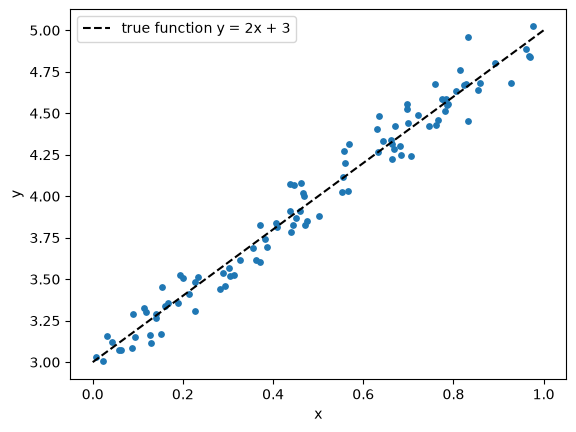

In [27]:
def generate_data(n=100, noise=0.1, seed=42):
    """Stand-in for the HW2 generator: y = 2x + 3 + Gaussian noise, x uniform in [0, 1]."""
    rng = np.random.default_rng(seed)
    x = rng.uniform(0, 1, n)
    y = 2 * x + 3 + rng.normal(0, noise, n)
    return x, y

x_data, y_data = generate_data()
print("x range:", x_data.min().round(3), x_data.max().round(3))
print("y range:", y_data.min().round(3), y_data.max().round(3))   # roughly 3 to 5

plt.scatter(x_data, y_data, s=15)
plt.plot([0, 1], [3, 5], "k--", label="true function y = 2x + 3")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

In [28]:
for name in ["relu", "sigmoid", "tanh"]:
    ws, bs, _, _ = fit_neuron(x_data, y_data, name, "squared error",
                              learning_rate=0.1, epochs=50, w0=0.5, b0=0.5)
    mse = mean_squared_error(x_data, y_data, name, ws[-1], bs[-1])
    print(f"{name:<8} final w={ws[-1]:.3f}  b={bs[-1]:.3f}  MSE={mse:.4f}")

relu     final w=2.022  b=3.000  MSE=0.0097
sigmoid  final w=2.930  b=6.150  MSE=9.1449
tanh     final w=1.881  b=3.974  MSE=9.1423


In [29]:
# Gradients returned by return_grad match the parameter update: new = old - lr * grad
w0, b0, lr = 0.3, 0.2, 0.05
w1, b1, gw, gb = train_neuron((0.8, 3.5), lr, w0, b0,
                              squared_error_derivative, relu_derivative,
                              activation=relu, return_grad=True)
assert np.isclose(w1, w0 - lr * gw) and np.isclose(b1, b0 - lr * gb)

# The flag does not change the update itself
w2, b2 = train_neuron((0.8, 3.5), lr, w0, b0,
                      squared_error_derivative, relu_derivative, activation=relu)
assert np.isclose(w1, w2) and np.isclose(b1, b2)

# fit_neuron returns one row per update
ws, bs, gws, gbs = fit_neuron(x_data, y_data, "relu", "squared error", 0.1, 3, 0.5, 0.5)
assert len(ws) == len(bs) == len(gws) == len(gbs) == 3 * len(x_data)

# ReLU recovers roughly the true function; sigmoid cannot reach targets above 1
ws, bs, _, _ = fit_neuron(x_data, y_data, "relu", "squared error", 0.1, 50, 0.5, 0.5)
assert abs(ws[-1] - 2) < 0.3 and abs(bs[-1] - 3) < 0.3
ws, bs, _, _ = fit_neuron(x_data, y_data, "sigmoid", "squared error", 0.1, 50, 0.5, 0.5)
assert mean_squared_error(x_data, y_data, "sigmoid", ws[-1], bs[-1]) > 1.0

# ReLU starting at exactly (0, 0) never moves (derivative at zero is 0)
ws, bs, _, _ = fit_neuron(x_data, y_data, "relu", "squared error", 0.1, 3, 0.0, 0.0)
assert ws[-1] == 0.0 and bs[-1] == 0.0
print("Q9 setup tests passed.")

Q9 setup tests passed.


In [31]:
# Animation 1 (required): ReLU + squared error. The model should swing onto the data
ani_relu = animate_fit(x_data, y_data, "relu", "squared error",
                       learning_rate=0.1, n_updates=200, step=4, w0=0.5, b0=0.5)
HTML(ani_relu.to_jshtml())

In [32]:
# Animation 2: sigmoid + squared error. The model should climb toward 1 and get stuck
ani_sigmoid = animate_fit(x_data, y_data, "sigmoid", "squared error",
                          learning_rate=0.1, n_updates=200, step=4, w0=0.5, b0=0.5)
HTML(ani_sigmoid.to_jshtml())

In [33]:
ws, bs, _, _ = fit_neuron(x_data, y_data, "relu", "squared error", 0.1, 2, 0.5, 0.5)
print(f"after 200 updates: w={ws[199]:.3f}, b={bs[199]:.3f}")
print("MSE:", round(mean_squared_error(x_data, y_data, "relu", ws[199], bs[199]), 4))

after 200 updates: w=2.045, b=2.989
MSE: 0.0098


In [34]:
def mse_by_epoch(x, y, activation_name, ws, bs, n_records):
    """MSE on (x, y) at the end of each epoch, from fit_neuron's per-update output."""
    activation, _ = ACTIVATIONS[activation_name]
    ends = np.arange(n_records - 1, len(ws), n_records)        # last update of each epoch
    return np.array([np.mean((activation(ws[i] * x + bs[i]) - y) ** 2) for i in ends])

# ---- Experiment A: raw targets, every activation with both costs ----
print(f"{'activation':<9}{'cost':<15}{'final w':>12}{'final b':>12}{'MSE':>14}")
with np.errstate(all="ignore"):                  # cross-entropy on raw targets can overflow
    for act_name in ["relu", "sigmoid", "tanh"]:
        for cost_name in ["squared error", "cross-entropy"]:
            ws, bs, _, _ = fit_neuron(x_data, y_data, act_name, cost_name,
                                      learning_rate=0.1, epochs=50, w0=0.5, b0=0.5)
            mse = mean_squared_error(x_data, y_data, act_name, ws[-1], bs[-1])
            print(f"{act_name:<9}{cost_name:<15}{ws[-1]:>12.3g}{bs[-1]:>12.3g}{mse:>14.4g}")

activationcost                final w     final b           MSE
relu     squared error          2.02           3      0.009744
relu     cross-entropy      7.97e+14    1.49e+15     3.558e+30
sigmoid  squared error          2.93        6.15         9.145
sigmoid  cross-entropy          13.8        31.9         9.141
tanh     squared error          1.88        3.97         9.142
tanh     cross-entropy          7.92        16.9         9.141


records clipped: 1
combination                    epoch 1   epoch 5  epoch 20  epoch 100
relu + squared error            0.0113    0.0025    0.0024     0.0024
sigmoid + squared error         0.0554    0.0174    0.0034     0.0026
sigmoid + cross-entropy         0.0208    0.0028    0.0028     0.0028
tanh + squared error            0.0056    0.0045    0.0045     0.0045


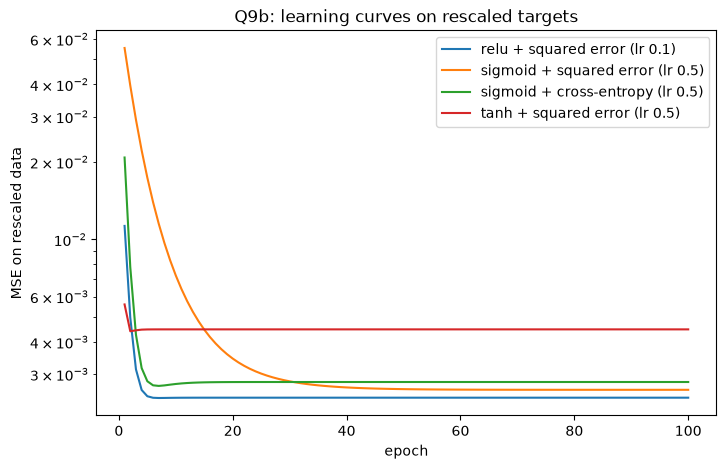

In [35]:
# ---- Experiment B: rescale targets to [0, 1] so sigmoid, tanh, and cross-entropy are valid ----
# The true function becomes y_scaled = x. Clipping touches only records whose noise pushes
# them outside [0, 1] (one record on my data).
y_scaled = np.clip((y_data - 3) / 2, 0, 1)
print("records clipped:", int(np.sum(((y_data - 3) / 2 < 0) | ((y_data - 3) / 2 > 1))))

configs = [  # (activation, cost, learning rate, initial w=b)
    ("relu",    "squared error", 0.1, 0.5),     # ReLU needs a nonzero start (see 9 setup)
    ("sigmoid", "squared error", 0.5, 0.0),
    ("sigmoid", "cross-entropy", 0.5, 0.0),
    ("tanh",    "squared error", 0.5, 0.0),
]
n = len(x_data)
plt.figure(figsize=(8, 5))
print(f"{'combination':<28}{'epoch 1':>10}{'epoch 5':>10}{'epoch 20':>10}{'epoch 100':>11}")
for act_name, cost_name, lr, init in configs:
    ws, bs, _, _ = fit_neuron(x_data, y_scaled, act_name, cost_name, lr, 100, init, init)
    curve = mse_by_epoch(x_data, y_scaled, act_name, ws, bs, n)
    plt.plot(range(1, 101), curve, label=f"{act_name} + {cost_name} (lr {lr})")
    print(f"{act_name + ' + ' + cost_name:<28}{curve[0]:>10.4f}{curve[4]:>10.4f}"
          f"{curve[19]:>10.4f}{curve[99]:>11.4f}")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE on rescaled data")
plt.title("Q9b: learning curves on rescaled targets"); plt.legend(); plt.show()

lr          MSE ep 1    MSE ep 5   MSE ep 50   final w   final b   max |w|
0.001          8.255       3.038     0.01078      1.88      3.05       1.9
0.01          0.8605     0.01025    0.009604      2.00      3.00       2.0
0.1         0.009991    0.009755    0.009744      2.02      3.00       2.1
1            0.04909     0.04812     0.04812      1.92      2.84       3.4
10             16.09       16.09       16.09   -174.99   -427.61     175.0


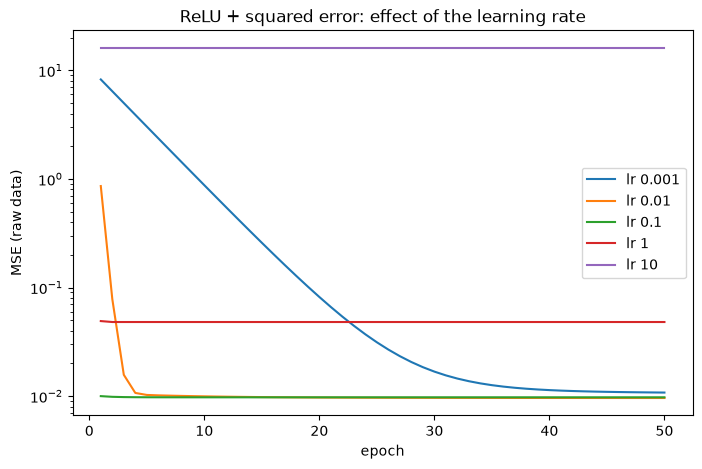

In [36]:
learning_rates = [0.001, 0.01, 0.1, 1, 10]
n = len(x_data)

# Same start (w = b = 0.5), 50 epochs, only the learning rate changes
with np.errstate(all="ignore"):        # the lr = 10 run produces huge numbers
    runs = {lr: fit_neuron(x_data, y_data, "relu", "squared error", lr, 50, 0.5, 0.5)
            for lr in learning_rates}

print(f"{'lr':<8}{'MSE ep 1':>12}{'MSE ep 5':>12}{'MSE ep 50':>12}"
      f"{'final w':>10}{'final b':>10}{'max |w|':>10}")
curves = {}
for lr, (ws, bs, _, _) in runs.items():
    curve = mse_by_epoch(x_data, y_data, "relu", ws, bs, n)
    curves[lr] = curve
    print(f"{lr:<8}{curve[0]:>12.4g}{curve[4]:>12.4g}{curve[49]:>12.4g}"
          f"{ws[-1]:>10.2f}{bs[-1]:>10.2f}{np.abs(ws).max():>10.1f}")

# Learning curves for all five rates
plt.figure(figsize=(8, 5))
for lr, curve in curves.items():
    plt.plot(range(1, 51), curve, label=f"lr {lr}")
plt.yscale("log")
plt.xlabel("epoch"); plt.ylabel("MSE (raw data)")
plt.title("ReLU + squared error: effect of the learning rate")
plt.legend(); plt.show()

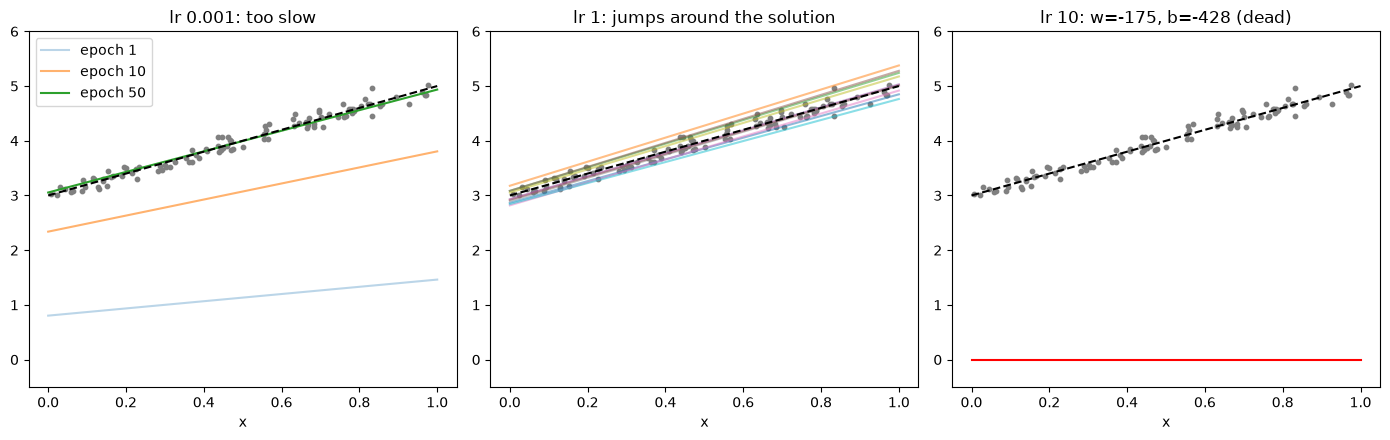

In [37]:
# Extreme examples: what the model actually looks like
xs = np.linspace(0, 1, 100)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

# lr = 0.001: slow. The model after epochs 1, 10, and 50
ws, bs, _, _ = runs[0.001]
for ep, alpha in [(1, 0.3), (10, 0.6), (50, 1.0)]:
    i = ep * n - 1
    axes[0].plot(xs, relu(ws[i] * xs + bs[i]), alpha=alpha, label=f"epoch {ep}")
axes[0].set_title("lr 0.001: too slow"); axes[0].legend()

# lr = 1: the model after each of the last 10 updates, jumping around
ws, bs, _, _ = runs[1]
for i in range(len(ws) - 10, len(ws)):
    axes[1].plot(xs, relu(ws[i] * xs + bs[i]), alpha=0.5)
axes[1].set_title("lr 1: jumps around the solution")

# lr = 10: the final model
ws, bs, _, _ = runs[10]
axes[2].plot(xs, relu(ws[-1] * xs + bs[-1]), "r")
axes[2].set_title(f"lr 10: w={ws[-1]:.0f}, b={bs[-1]:.0f} (dead)")

for ax in axes:
    ax.scatter(x_data, y_data, s=10, color="gray")
    ax.plot(xs, 2 * xs + 3, "k--")
    ax.set_ylim(-0.5, 6); ax.set_xlabel("x")
plt.tight_layout(); plt.show()

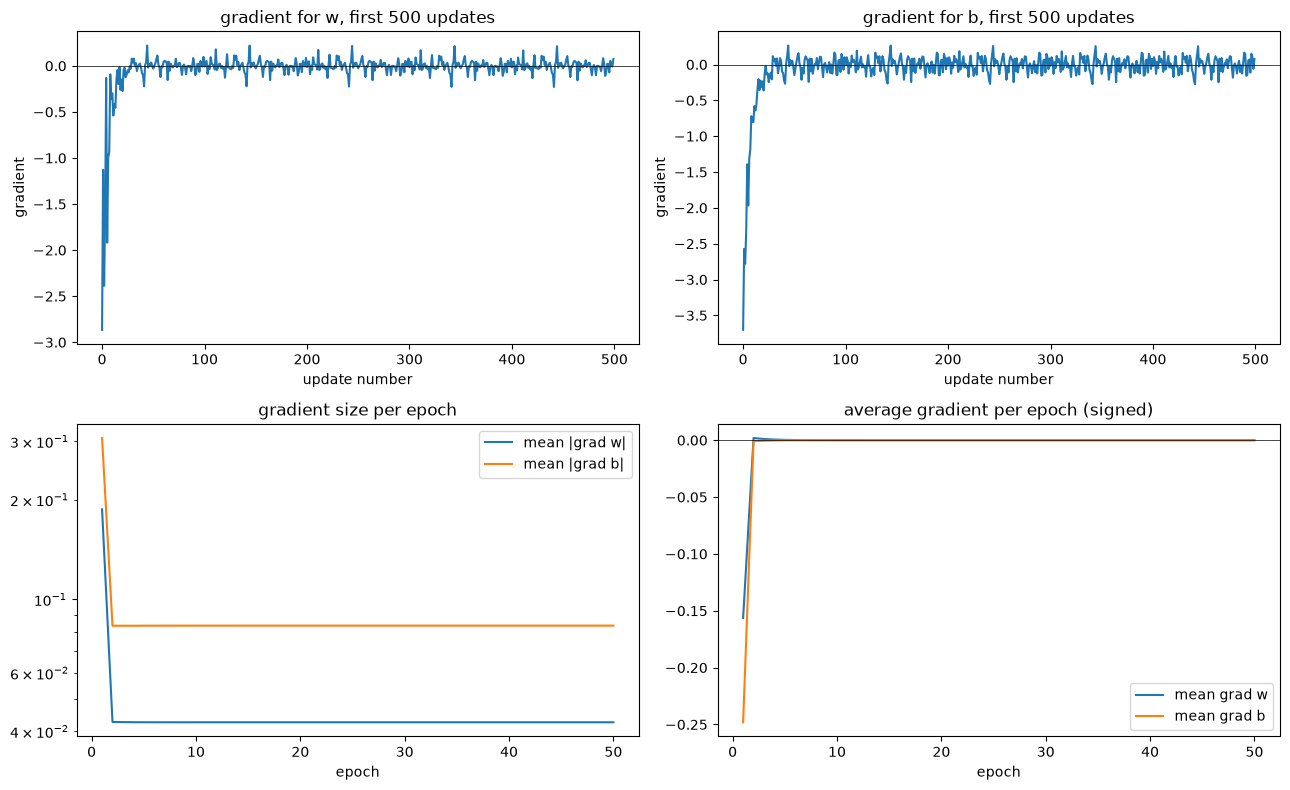

first 5 updates, grad w: [-2.86 -1.13 -2.39 -1.62 -0.13]
first 5 updates, grad b: [-3.7  -2.57 -2.78 -2.33 -1.39]
epoch    mean grad w  mean grad b  mean |grad w|  mean |grad b|
1            -0.1564      -0.2481         0.1870         0.3070
2             0.0019      -0.0009         0.0427         0.0833
5             0.0003      -0.0001         0.0426         0.0833
20            0.0000      -0.0000         0.0426         0.0834
50            0.0000      -0.0000         0.0426         0.0834


In [38]:
# Same run as before: ReLU + squared error, lr 0.1, 50 epochs.
# fit_neuron already records the gradient used in every update.
epochs = 50
ws, bs, gws, gbs = fit_neuron(x_data, y_data, "relu", "squared error",
                              learning_rate=0.1, epochs=epochs, w0=0.5, b0=0.5)
n = len(x_data)

# One row per epoch, one column per record: gradient used for each update
grad_w_by_epoch = gws.reshape(epochs, n)
grad_b_by_epoch = gbs.reshape(epochs, n)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# Top row: the gradient at every single update, for the first 500 updates (5 epochs)
axes[0, 0].plot(gws[:500])
axes[0, 0].set_title("gradient for w, first 500 updates")
axes[0, 1].plot(gbs[:500])
axes[0, 1].set_title("gradient for b, first 500 updates")
for ax in axes[0]:
    ax.axhline(0, color="k", lw=0.5)
    ax.set_xlabel("update number"); ax.set_ylabel("gradient")

# Bottom left: how BIG the gradients are, epoch by epoch (mean absolute value)
ep = np.arange(1, epochs + 1)
axes[1, 0].plot(ep, np.abs(grad_w_by_epoch).mean(axis=1), label="mean |grad w|")
axes[1, 0].plot(ep, np.abs(grad_b_by_epoch).mean(axis=1), label="mean |grad b|")
axes[1, 0].set_yscale("log")
axes[1, 0].set_title("gradient size per epoch")
axes[1, 0].set_xlabel("epoch"); axes[1, 0].legend()

# Bottom right: the average SIGNED gradient per epoch (do the updates cancel out?)
axes[1, 1].plot(ep, grad_w_by_epoch.mean(axis=1), label="mean grad w")
axes[1, 1].plot(ep, grad_b_by_epoch.mean(axis=1), label="mean grad b")
axes[1, 1].axhline(0, color="k", lw=0.5)
axes[1, 1].set_title("average gradient per epoch (signed)")
axes[1, 1].set_xlabel("epoch"); axes[1, 1].legend()

plt.tight_layout(); plt.show()

# A few numbers to quote
print("first 5 updates, grad w:", np.round(gws[:5], 2))
print("first 5 updates, grad b:", np.round(gbs[:5], 2))
print(f"{'epoch':<7}{'mean grad w':>13}{'mean grad b':>13}{'mean |grad w|':>15}{'mean |grad b|':>15}")
for e in [1, 2, 5, 20, 50]:
    gw_e, gb_e = grad_w_by_epoch[e - 1], grad_b_by_epoch[e - 1]
    print(f"{e:<7}{gw_e.mean():>13.4f}{gb_e.mean():>13.4f}"
          f"{np.abs(gw_e).mean():>15.4f}{np.abs(gb_e).mean():>15.4f}")

In [39]:
def linear(z):
    return z

def linear_derivative(z):
    return np.ones_like(z, dtype=float)       # slope is 1 everywhere

ACTIVATIONS["linear"] = (linear, linear_derivative)

# Train with a linear activation. Start from w = b = 0, which killed ReLU earlier.
ws, bs, gws, gbs = fit_neuron(x_data, y_data, "linear", "squared error",
                              learning_rate=0.1, epochs=50, w0=0.0, b0=0.0)
print(f"linear + squared error: w={ws[-1]:.3f}, b={bs[-1]:.3f}, "
      f"MSE={mean_squared_error(x_data, y_data, 'linear', ws[-1], bs[-1]):.4f}")

# Reference: the exact least-squares line for this data
slope, intercept = np.polyfit(x_data, y_data, 1)
print(f"least squares:          w={slope:.3f}, b={intercept:.3f}, "
      f"MSE={np.mean((slope * x_data + intercept - y_data) ** 2):.4f}")

# Optional animation, same function as in 9a
ani_linear = animate_fit(x_data, y_data, "linear", "squared error",
                         learning_rate=0.1, n_updates=200, step=4, w0=0.0, b0=0.0)
HTML(ani_linear.to_jshtml())

linear + squared error: w=2.022, b=3.000, MSE=0.0097
least squares:          w=2.008, b=2.995, MSE=0.0096


In [40]:
# Compare with ReLU from the same starting point as before
ws_r, bs_r, _, _ = fit_neuron(x_data, y_data, "relu", "squared error", 0.1, 50, 0.5, 0.5)
ws_l, bs_l, _, _ = fit_neuron(x_data, y_data, "linear", "squared error", 0.1, 50, 0.5, 0.5)
print("ReLU and linear give identical trajectories from (0.5, 0.5):",
      np.allclose(ws_r, ws_l) and np.allclose(bs_r, bs_l))

# Learning-rate behavior (as in 9c)
for lr in [0.001, 0.01, 0.1, 1, 10]:
    with np.errstate(all="ignore"):
        ws, bs, _, _ = fit_neuron(x_data, y_data, "linear", "squared error", lr, 50, 0.0, 0.0)
    print(f"lr {lr:<6} final w={ws[-1]:.3f}, b={bs[-1]:.3f}")

ReLU and linear give identical trajectories from (0.5, 0.5): True
lr 0.001  final w=1.740, b=3.126
lr 0.01   final w=1.993, b=3.006
lr 0.1    final w=2.022, b=3.000
lr 1      final w=1.921, b=2.842
lr 10     final w=nan, b=nan
